<a href="https://colab.research.google.com/github/petermich84-boop/Hill-running-performance-analysis/blob/main/Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
from google.colab import files

# Ak súbor ešte nemáš nahraný vľavo v paneli, odkomentuj tieto 2 riadky:
# uploaded = files.upload()
# filename = list(uploaded.keys())[0]

filename = "cardioActivities.csv"
df = pd.read_csv(filename)

print("Pôvodný počet riadkov a stĺpcov:", df.shape)
print("Typy aktivít:", df["Type"].value_counts(dropna=False).to_dict())

# 1. Filtrovanie len na behy ("Running") a odstránenie úplných duplikátov
runs = df[df["Type"] == "Running"].copy()
runs = runs.drop_duplicates()

# 2. Dátum a čas
runs["Date_dt"] = pd.to_datetime(runs["Date"], errors="coerce")
runs = runs.dropna(subset=["Date_dt"]).sort_values("Date_dt")

# 3. Číselné stĺpce
for col in ["Distance (km)", "Average Speed (km/h)", "Climb (m)", "Average Heart Rate (bpm)"]:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors="coerce")

# Pomocná funkcia na prevod 'MM:SS' alebo 'HH:MM:SS' na minúty
def time_to_minutes(val):
    if pd.isna(val):
        return np.nan
    parts = str(val).strip().split(":")
    try:
        parts = [float(p) for p in parts]
        if len(parts) == 2:      # MM:SS
            return parts[0] + parts[1] / 60.0
        elif len(parts) == 3:    # HH:MM:SS
            return parts[0] * 60.0 + parts[1] + parts[2] / 60.0
    except ValueError:
        return np.nan
    return np.nan

runs["duration_min"] = runs["Duration"].apply(time_to_minutes)
runs["pace_min_per_km"] = runs["Average Pace"].apply(time_to_minutes)

# Ak chýba Average Speed (km/h), dopočítame z Distance (km) a duration_min
mask_speed = runs["Average Speed (km/h)"].isna() & (runs["duration_min"] > 0)
runs.loc[mask_speed, "Average Speed (km/h)"] = (
    runs.loc[mask_speed, "Distance (km)"] / (runs.loc[mask_speed, "duration_min"] / 60.0)
)

# 4. Odstránenie neplatných alebo extrémnych záznamov (napr. 0 km alebo 0 minút)
runs = runs[(runs["Distance (km)"] > 0) & (runs["duration_min"] > 0)].copy()

# 5. Nové analytické metriky
runs["climb_per_km"] = np.where(
    runs["Climb (m)"].notna(),
    runs["Climb (m)"] / runs["Distance (km)"],
    np.nan
)

# Orientačná kategória pre šprinty/kopce (práh si upravíš podľa distribúcie v tvojom súbore)
runs["training_group"] = np.where(
    (runs["Distance (km)"] <= 5.0) & (runs["climb_per_km"] >= 25.0),
    "Short Hill / Sprint Candidate",
    np.where(
        runs["climb_per_km"] >= 25.0,
        "Long / Trail Hill Run",
        "Standard / Flat Run"
    )
)

print("\nPo vyčistení (len Running):", runs.shape)
print("\nRozdelenie kategórií:")
print(runs["training_group"].value_counts(dropna=False))

print("\nZákladné štatistiky vybraných stĺpcov:")
cols_to_show = [c for c in ["Distance (km)", "duration_min", "pace_min_per_km", "Average Speed (km/h)", "Climb (m)", "climb_per_km", "Average Heart Rate (bpm)"] if c in runs.columns]
print(runs[cols_to_show].describe().round(2))

# Uloženie vyčisteného súboru na stiahnutie
runs.to_csv("cardio_runs_cleaned.csv", index=False)
print("\nUložené ako cardio_runs_cleaned.csv")

Pôvodný počet riadkov a stĺpcov: (508, 14)
Typy aktivít: {'Running': 459, 'Cycling': 29, 'Walking': 18, 'Other': 2}

Po vyčistení (len Running): (459, 19)

Rozdelenie kategórií:
training_group
Standard / Flat Run      456
Long / Trail Hill Run      3
Name: count, dtype: int64

Základné štatistiky vybraných stĺpcov:
       Distance (km)  duration_min  pace_min_per_km  Average Speed (km/h)  \
count         459.00        459.00           459.00                459.00   
mean           11.38         62.22             5.46                 11.06   
std             4.94         28.68             0.47                  0.95   
min             0.76          5.25             2.90                  5.77   
25%             7.42         42.60             5.20                 10.50   
50%            10.81         60.32             5.47                 10.98   
75%            13.19         73.41             5.72                 11.52   
max            38.32        268.32            10.40                

In [4]:
# Príklad upravenej kategorizácie podľa distribúcie v tomto datasete:
# 1. Krátke kopcovité / intenzívne behy: do 6 km a climb_per_km >= 15 (alebo kratšie behy s vyšším prevýšením)
# 2. Kopcovité / trailové behy: nad 6 km a climb_per_km >= 15
# 3. Stredne kopcovité behy: climb_per_km medzi 10 a 15
# 4. Rovina / mierne prevýšenie: climb_per_km < 10

def categorize_run(row):
    cpk = row["climb_per_km"]
    dist = row["Distance (km)"]
    if cpk >= 15.0 and dist <= 6.0:
        return "Short / Sprint Hill Candidate"
    elif cpk >= 15.0:
        return "Long / Trail Hill Run"
    elif cpk >= 10.0:
        return "Moderate Climb Run"
    else:
        return "Flat / Low Climb Run"

runs["training_group_v2"] = runs.apply(categorize_run, axis=1)

print(runs["training_group_v2"].value_counts())
print("\nPriemery podľa novej kategórie:")
print(
    runs.groupby("training_group_v2")[
        ["Distance (km)", "duration_min", "pace_min_per_km", "Climb (m)", "climb_per_km", "Average Heart Rate (bpm)"]
    ].mean().round(2)
)

training_group_v2
Flat / Low Climb Run     273
Moderate Climb Run       108
Long / Trail Hill Run     78
Name: count, dtype: int64

Priemery podľa novej kategórie:
                       Distance (km)  duration_min  pace_min_per_km  \
training_group_v2                                                     
Flat / Low Climb Run            9.58         50.83             5.37   
Long / Trail Hill Run          16.44         94.52             5.73   
Moderate Climb Run             12.29         67.70             5.52   

                       Climb (m)  climb_per_km  Average Heart Rate (bpm)  
training_group_v2                                                         
Flat / Low Climb Run       65.92          6.71                    144.36  
Long / Trail Hill Run     282.17         17.21                    143.50  
Moderate Climb Run        159.94         12.91                    146.80  


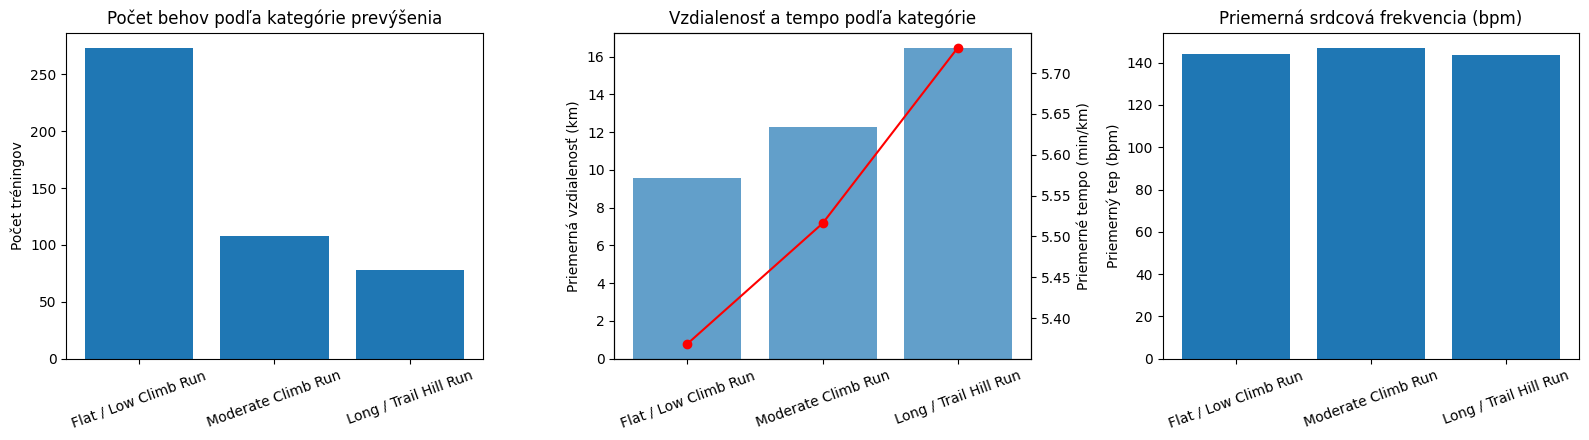

In [5]:
import matplotlib.pyplot as plt

# Pripravíme si súhrnnú tabuľku priamo z `runs`
summary = runs.groupby("training_group_v2").agg(
    count=("Distance (km)", "count"),
    avg_dist_km=("Distance (km)", "mean"),
    avg_pace=("pace_min_per_km", "mean"),
    avg_climb_per_km=("climb_per_km", "mean"),
    avg_hr=("Average Heart Rate (bpm)", "mean")
).reindex(["Flat / Low Climb Run", "Moderate Climb Run", "Long / Trail Hill Run"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Počet behov
axes[0].bar(summary.index, summary["count"])
axes[0].set_title("Počet behov podľa kategórie prevýšenia")
axes[0].set_ylabel("Počet tréningov")
axes[0].tick_params(axis="x", rotation=20)

# 2. Priemerná vzdialenosť a tempo
ax2_twin = axes[1].twinx()
axes[1].bar(summary.index, summary["avg_dist_km"], alpha=0.7, label="Vzdialenosť (km)")
ax2_twin.plot(summary.index, summary["avg_pace"], marker="o", color="red", label="Tempo (min/km)")
axes[1].set_title("Vzdialenosť a tempo podľa kategórie")
axes[1].set_ylabel("Priemerná vzdialenosť (km)")
ax2_twin.set_ylabel("Priemerné tempo (min/km)")
axes[1].tick_params(axis="x", rotation=20)

# 3. Priemerný tep (bpm)
axes[2].bar(summary.index, summary["avg_hr"])
axes[2].set_title("Priemerná srdcová frekvencia (bpm)")
axes[2].set_ylabel("Priemerný tep (bpm)")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("hill_runs_overview.png", dpi=200, bbox_inches="tight")
plt.show()